# Albion Basket: joining PostgreSQL and MongoDB in pandas (Module 6)

This notebook pulls **orders** from PostgreSQL and **reviews** from MongoDB, cleans them,
answers the five business questions with charts, then exports curated tables to the warehouse `raw` schema for dbt.

Run order: `generate_data.py → load_pg.py → mongo_load.py →` **this notebook** `→ dbt build`.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text, Numeric, Integer, String, Date, DateTime, Boolean
from pymongo import MongoClient

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
load_dotenv(ROOT / ".env")
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('PG_USER')}:{os.getenv('PG_PASSWORD')}"
    f"@{os.getenv('PG_HOST', 'localhost')}:{os.getenv('PG_PORT', '5432')}/{os.getenv('PG_DB', 'albion')}")
mongo = MongoClient(os.getenv("MONGO_URI", "mongodb://localhost:27017"))[os.getenv("MONGO_DB", "albion")]
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format)

Matplotlib is building the font cache; this may take a moment.


## 1. Extract

In [2]:
orders = pd.read_sql("SELECT order_id, customer_id, order_ts, channel, total_gbp, vat_gbp, delivery_fee_gbp, "
                     "postcode, postcode_area, region, nation, delivery_band FROM shop.v_orders", engine)
items = pd.read_sql("SELECT order_id, sku, quantity, unit_price_gbp FROM shop.order_items", engine)
products = pd.read_sql("SELECT p.sku, p.name, p.category, p.vat_band, v.rate AS vat_rate, p.unit_price_gbp "
                       "FROM shop.products p JOIN shop.vat_rates v USING (vat_band)", engine)
customers = pd.read_sql("SELECT c.customer_id, c.full_name, c.email, c.signup_date, a.postcode, a.postcode_area, r.region, r.nation "
                        "FROM shop.customers c JOIN shop.addresses a ON a.address_id = c.home_address_id "
                        "JOIN shop.regions r ON r.postcode_area = a.postcode_area", engine)
reviews = pd.json_normalize(list(mongo.reviews.find({}, {"text": 0})))
holidays = pd.read_csv(ROOT / "data" / "reference" / "uk_bank_holidays.csv", parse_dates=["holiday_date"])
{name: df.shape for name, df in dict(orders=orders, items=items, products=products,
                                     customers=customers, reviews=reviews).items()}

{'orders': (48016, 12),
 'items': (478470, 4),
 'products': (200, 6),
 'customers': (6000, 8),
 'reviews': (14756, 10)}

## 2. Clean: dtypes, nulls, duplicates, UK time

In [3]:
money = ["total_gbp", "vat_gbp", "delivery_fee_gbp"]
orders[money] = orders[money].astype(float)
items["unit_price_gbp"] = items["unit_price_gbp"].astype(float)
products[["unit_price_gbp", "vat_rate"]] = products[["unit_price_gbp", "vat_rate"]].astype(float)

# Postgres returns timestamptz as UTC; convert to UK local time so days and months are British days
orders["order_ts"] = pd.to_datetime(orders["order_ts"], utc=True).dt.tz_convert("Europe/London")
orders["order_date"] = orders["order_ts"].dt.tz_localize(None).dt.normalize()
orders["month"] = orders["order_ts"].dt.tz_localize(None).dt.to_period("M")

reviews = reviews.rename(columns={"_id": "review_id", "product.name": "product_name", "product.category": "category"})
reviews["review_ts"] = pd.to_datetime(reviews["review_ts"], utc=True).dt.tz_convert("Europe/London")
reviews["customer_id"] = reviews["customer_id"].astype("Int64")      # nullable: unverified reviews have none
reviews["order_id"] = reviews["order_id"].astype("Int64")

checks = {
    "duplicate order_ids": orders["order_id"].duplicated().sum(),
    "duplicate review_ids": reviews["review_id"].duplicated().sum(),
    "null totals": orders["total_gbp"].isna().sum(),
    "reviews with no customer (unverified)": reviews["customer_id"].isna().sum(),
    "items without a product": (~items["sku"].isin(products["sku"])).sum(),
}
orders = orders.drop_duplicates("order_id"); reviews = reviews.drop_duplicates("review_id")
checks

{'duplicate order_ids': np.int64(0),
 'duplicate review_ids': np.int64(0),
 'null totals': np.int64(0),
 'reviews with no customer (unverified)': np.int64(400),
 'items without a product': np.int64(0)}

In [4]:
# VAT reconciliation: does stored order VAT equal VAT recomputed from the lines?
lines = items.merge(products[["sku", "category", "vat_band", "vat_rate"]], on="sku", how="left", validate="many_to_one")
lines["gross_gbp"] = lines["quantity"] * lines["unit_price_gbp"]
# round half-up per line, like the till does (float .round(2) is banker's-style and drifts by 1p)
lines["vat_gbp"] = np.floor(lines["gross_gbp"] * lines["vat_rate"] / (1 + lines["vat_rate"]) * 100 + 0.5 + 1e-9) / 100
recon = lines.groupby("order_id")["vat_gbp"].sum().rename("vat_from_lines").to_frame().join(orders.set_index("order_id")["vat_gbp"])
print(f"orders where VAT differs by more than 1p: {(recon['vat_from_lines'] - recon['vat_gbp']).abs().gt(0.01).sum()}")

orders where VAT differs by more than 1p: 0


## Q1. Which regions and nations drive revenue, and which are growing fastest?

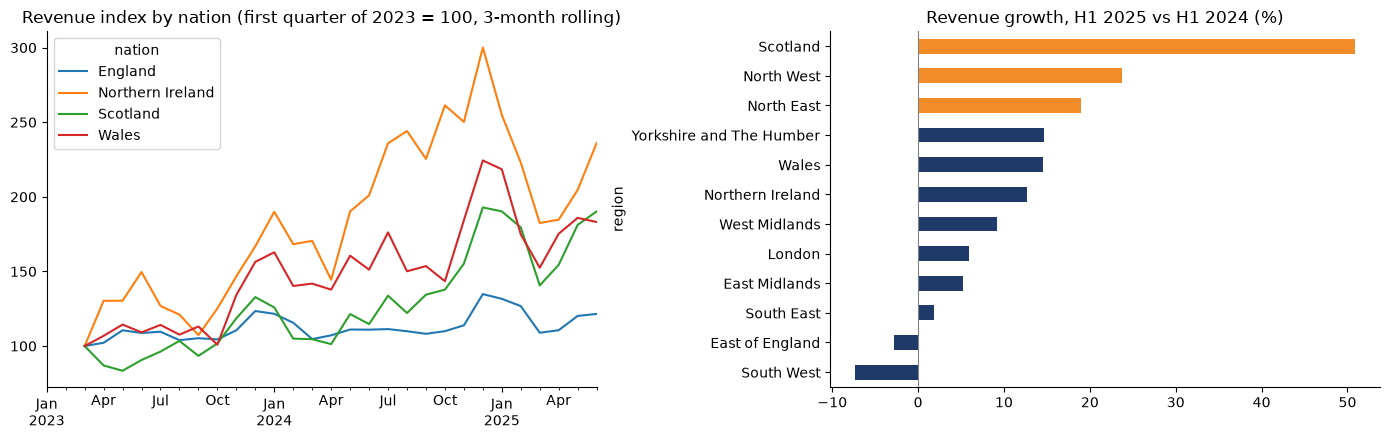

,H1 2024,H1 2025,growth_%,share_of_revenue_%
region,,,,
Scotland,"81,701.00","123,266.60",50.90,10.80
North West,"86,340.70","106,855.20",23.80,10.80
North East,"35,145.40","41,827.70",19.00,4.10
Yorkshire and The Humber,"69,259.00","79,409.00",14.70,8.20
Wales,"50,181.20","57,482.40",14.50,5.70
Northern Ireland,"29,962.00","33,756.60",12.70,3.30
West Midlands,"72,663.80","79,343.20",9.20,8.60
London,"95,320.80","100,974.40",5.90,11.50
East Midlands,"59,232.30","62,336.90",5.20,7.00


In [5]:
by_region_month = (orders.groupby(["region", "month"])["total_gbp"].sum().unstack("region"))
nation_month = orders.groupby(["nation", "month"])["total_gbp"].sum().unstack("nation")

h1 = lambda y: orders[(orders["order_ts"].dt.year == y) & (orders["order_ts"].dt.month <= 6)]
growth = pd.DataFrame({"H1 2024": h1(2024).groupby("region")["total_gbp"].sum(),
                       "H1 2025": h1(2025).groupby("region")["total_gbp"].sum()})
growth["growth_%"] = (growth["H1 2025"] / growth["H1 2024"] - 1) * 100
growth["share_of_revenue_%"] = orders.groupby("region")["total_gbp"].sum() / orders["total_gbp"].sum() * 100
growth = growth.sort_values("growth_%", ascending=False)

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.5))
idx = (nation_month / nation_month.iloc[:3].mean()) * 100
idx.index = idx.index.to_timestamp(); idx.rolling(3).mean().plot(ax=a)
a.set_title("Revenue index by nation (first quarter of 2023 = 100, 3-month rolling)"); a.set_xlabel("")
growth["growth_%"].plot.barh(ax=b, color=["#F28C28" if g > 15 else "#1F3A68" for g in growth["growth_%"]])
b.invert_yaxis(); b.set_title("Revenue growth, H1 2025 vs H1 2024 (%)"); b.axvline(0, color="grey", lw=0.8)
plt.tight_layout(); plt.savefig(FIG / "q1_region_growth.png", dpi=120); plt.show()
growth.round(1)

## Q2. How do bank holidays, Black Friday and Christmas change daily orders?

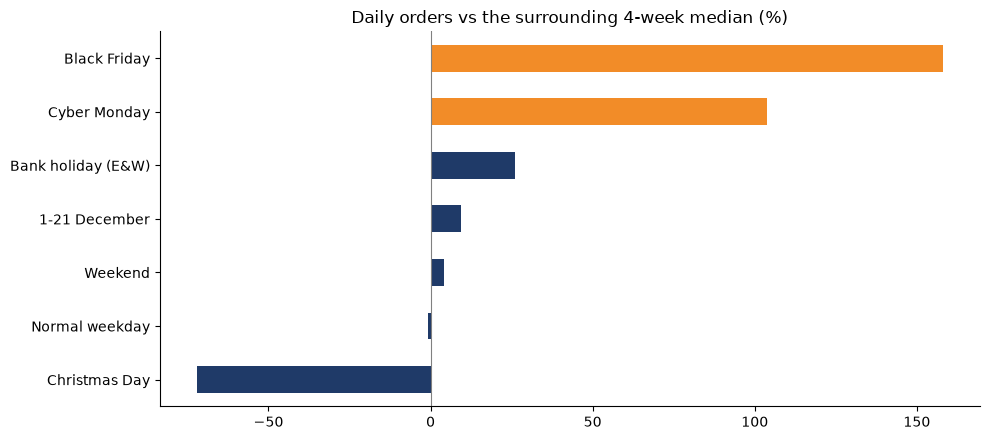

,days,avg_orders,vs_baseline_pct
day_type,,,
Christmas Day,2,16.00,-72.00
Normal weekday,596,49.80,-0.90
Weekend,249,52.40,4.10
1-21 December,41,82.50,9.30
Bank holiday (E&W),20,62.40,26.10
Cyber Monday,2,150.50,103.70
Black Friday,2,172.50,158.00


In [6]:
daily = orders.groupby("order_date").size().rename("orders").to_frame()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
ew = set(holidays.loc[holidays["division"] == "england-and-wales", "holiday_date"])

def black_friday(year):
    nov1 = pd.Timestamp(year, 11, 1)
    return nov1 + pd.Timedelta(days=(3 - nov1.weekday()) % 7 + 22)

bf = {black_friday(y) for y in daily.index.year.unique()}
cm = {d + pd.Timedelta(days=3) for d in bf}

def day_type(d):
    if d in bf: return "Black Friday"
    if d in cm: return "Cyber Monday"
    if d.month == 12 and d.day == 25: return "Christmas Day"
    if d.month == 12 and d.day <= 21: return "1-21 December"
    if d in ew: return "Bank holiday (E&W)"
    return "Weekend" if d.weekday() >= 5 else "Normal weekday"

daily["day_type"] = [day_type(d) for d in daily.index]
# remove trend so 2025 days aren't flattered by growth: index each day against its 28-day centred median
daily["baseline"] = daily["orders"].rolling(28, center=True, min_periods=7).median()
daily["vs_baseline_%"] = (daily["orders"] / daily["baseline"] - 1) * 100
uplift = daily.groupby("day_type").agg(days=("orders", "size"), avg_orders=("orders", "mean"),
                                       vs_baseline_pct=("vs_baseline_%", "mean")).sort_values("vs_baseline_pct")
ax = uplift["vs_baseline_pct"].plot.barh(color=["#1F3A68" if v < 50 else "#F28C28" for v in uplift["vs_baseline_pct"]])
ax.axvline(0, color="grey", lw=0.8); ax.set_title("Daily orders vs the surrounding 4-week median (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "q2_calendar_effects.png", dpi=120); plt.show()
uplift.round(1)

## Q3. Which products get the worst reviews, and does that hurt repeat purchases?

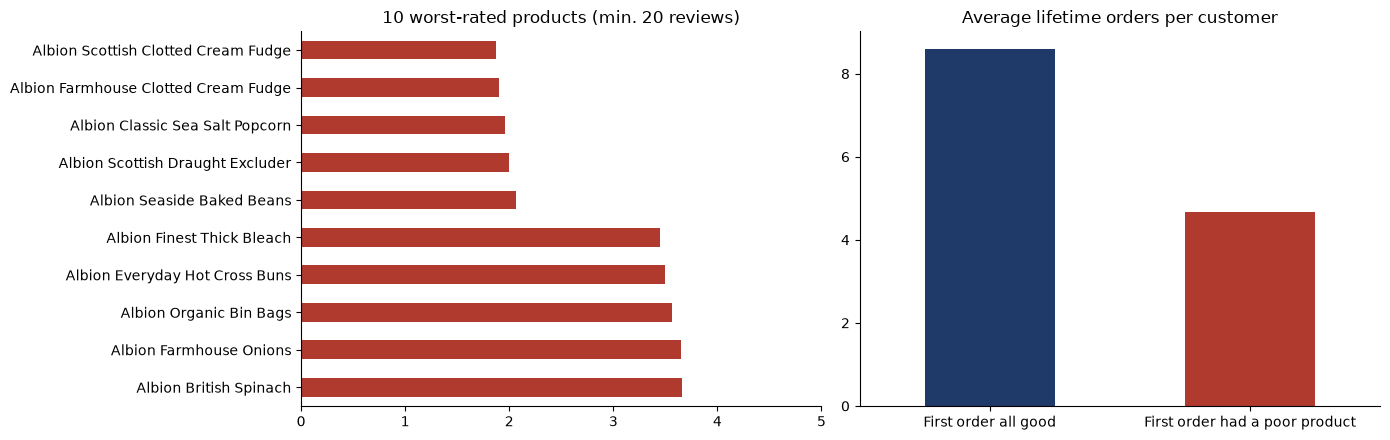

,avg_rating,reviews,name,category
sku,,,,
AB-10097,1.88,24,Albion Scottish Clotted Cream Fudge,Snacks & Confectionery
AB-10085,1.90,122,Albion Farmhouse Clotted Cream Fudge,Snacks & Confectionery
AB-10098,1.96,23,Albion Classic Sea Salt Popcorn,Snacks & Confectionery
AB-10185,2.00,24,Albion Scottish Draught Excluder,Energy Saving
AB-10062,2.07,60,Albion Seaside Baked Beans,Pantry
AB-10135,3.45,31,Albion Finest Thick Bleach,Household
AB-10028,3.50,86,Albion Everyday Hot Cross Buns,Bakery
AB-10137,3.57,46,Albion Organic Bin Bags,Household
AB-10019,3.65,96,Albion Farmhouse Onions,Fresh Produce


,customers,repeat_rate,avg_orders
first_order_had_poor,,,
First order all good,5127,0.98,8.59
First order had a poor product,851,0.92,4.67


In [7]:
prod_rating = (reviews.groupby("sku").agg(avg_rating=("rating", "mean"), reviews=("rating", "size"))
               .join(products.set_index("sku")[["name", "category"]]))
worst = prod_rating[prod_rating["reviews"] >= 20].sort_values("avg_rating").head(10)

# Did a customer's FIRST order contain a poorly rated product (avg < 2.5)?
poor = set(prod_rating.query("avg_rating < 2.5 and reviews >= 20").index)
first_orders = orders.sort_values("order_ts").groupby("customer_id").head(1)[["customer_id", "order_id"]]
first_has_poor = (items[items["order_id"].isin(first_orders["order_id"])]
                  .assign(poor=lambda d: d["sku"].isin(poor)).groupby("order_id")["poor"].any())
cust = first_orders.assign(first_order_had_poor=first_orders["order_id"].map(first_has_poor).fillna(False))
cust = cust.merge(orders.groupby("customer_id").size().rename("n_orders"), on="customer_id")
cust["repeat"] = cust["n_orders"] >= 2
repeat_cmp = cust.groupby("first_order_had_poor").agg(customers=("customer_id", "size"),
                                                      repeat_rate=("repeat", "mean"), avg_orders=("n_orders", "mean"))
repeat_cmp.index = repeat_cmp.index.map({True: "First order had a poor product", False: "First order all good"})

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.5))
worst.set_index("name")["avg_rating"].plot.barh(ax=a, color="#B03A2E"); a.invert_yaxis()
a.set_title("10 worst-rated products (min. 20 reviews)"); a.set_xlim(0, 5); a.set_ylabel("")
repeat_cmp["avg_orders"].plot.bar(ax=b, color=["#1F3A68", "#B03A2E"], rot=0)
b.set_title("Average lifetime orders per customer"); b.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "q3_reviews_repeat.png", dpi=120); plt.show()
display(worst.round(2)); repeat_cmp.round(3)

## Q4. How much VAT did we collect per quarter and per UK tax year?

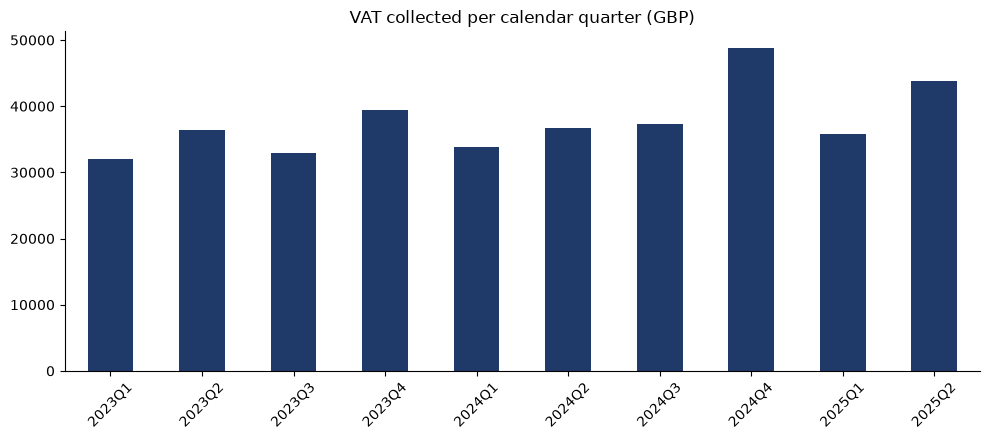

,vat_gbp,orders,first_day,last_day
tax_year,,,,
2022/23,"33,931.37",4346,2023-01-01,2023-04-05
2023/24,"143,031.79",18367,2023-04-06,2024-04-05
2024/25,"159,229.67",20249,2024-04-06,2025-04-05
2025/26,"40,880.47",5054,2025-04-06,2025-06-30


,gross_gbp,vat_gbp
vat_band,,
reduced,"1,058,988.68","50,428.98"
standard,"1,958,309.64","326,644.32"
zero,"1,428,026.78",0.00


In [8]:
ts_local = orders["order_ts"].dt.tz_localize(None)
orders["vat_quarter"] = ts_local.dt.to_period("Q").astype(str)
start = np.where((ts_local.dt.month > 4) | ((ts_local.dt.month == 4) & (ts_local.dt.day >= 6)),
                 ts_local.dt.year, ts_local.dt.year - 1)
orders["tax_year"] = [f"{s}/{str(s + 1)[-2:]}" for s in start]

vat_q = orders.groupby("vat_quarter")[["total_gbp", "vat_gbp"]].sum()
vat_ty = orders.groupby("tax_year").agg(vat_gbp=("vat_gbp", "sum"), orders=("order_id", "size"),
                                         first_day=("order_date", "min"), last_day=("order_date", "max"))
vat_band = lines.groupby("vat_band")[["gross_gbp", "vat_gbp"]].sum()

ax = vat_q["vat_gbp"].plot.bar(color="#1F3A68", rot=45)
ax.set_title("VAT collected per calendar quarter (GBP)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "q4_vat_quarter.png", dpi=120); plt.show()
display(vat_ty); vat_band

## Q5. What share of orders ship to surcharge zones?

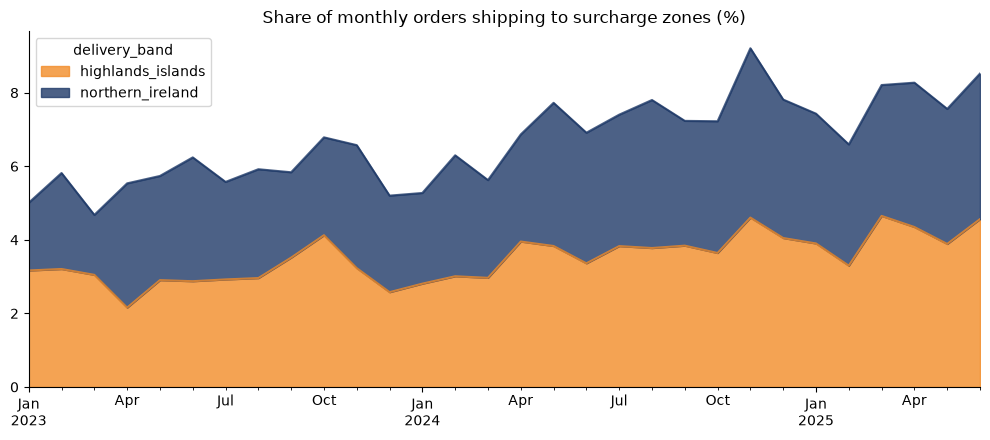

H&I + NI share, first 6 months vs last 6 months: 5.5 7.76


delivery_band
mainland            93.22
highlands_islands    3.54
northern_ireland     3.24
Name: proportion, dtype: float64

orders  surcharge_revenue_gbp
delivery_band     postcode_area                               
highlands_islands HS                338               2,254.49
                  IV                609               4,002.60
                  KW                444               2,889.18
                  ZE                307               2,018.17
northern_ireland  BT               1556               8,739.60

In [9]:
band_share = orders["delivery_band"].value_counts(normalize=True).mul(100)
band_month = (orders.groupby(["month", "delivery_band"]).size().unstack().pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100))
band_month.index = band_month.index.to_timestamp()
by_area = (orders[orders["delivery_band"] != "mainland"].groupby(["delivery_band", "postcode_area"])
           .agg(orders=("order_id", "size"), surcharge_revenue_gbp=("delivery_fee_gbp", "sum")))

ax = band_month[["highlands_islands", "northern_ireland"]].plot.area(alpha=0.8, color=["#F28C28", "#1F3A68"])
ax.set_title("Share of monthly orders shipping to surcharge zones (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "q5_surcharge_share.png", dpi=120); plt.show()
print("H&I + NI share, first 6 months vs last 6 months:",
      band_month[["highlands_islands", "northern_ireland"]].sum(axis=1).iloc[:6].mean().round(2),
      band_month[["highlands_islands", "northern_ireland"]].sum(axis=1).iloc[-6:].mean().round(2))
display(band_share.round(2)); by_area

## Bonus: basket abandonment from MongoDB events

In [10]:
sys.path.insert(0, str(ROOT))
from mongo.pipelines import BASKET_ABANDONMENT_BY_DEVICE
pd.DataFrame(list(mongo.events.aggregate(BASKET_ABANDONMENT_BY_DEVICE))).rename(columns={"_id": "device"})

,device,basket_sessions,checkouts,abandonment_rate
0,mobile,6807,2552,0.63
1,tablet,921,460,0.50
2,desktop,3573,2185,0.39


## Findings

**Q1 Regions.** England brings in about 80% of revenue; the South East (12.6%) and London (11.5%) are the biggest regions.
But growth is in the north: **Scotland grew 51%** (H1 2025 vs H1 2024), the North West 24% and the North East 19%,
while the South West (−7%) and East of England (−3%) shrank. Scotland is now level with the North West in revenue share.

**Q2 Calendar.** Against the surrounding four-week median, **Black Friday runs +158%** and Cyber Monday +104%.
England & Wales bank holidays add about **+26%** (long-weekend stock-ups). December 1–21 averages 83 orders a day
against 50 on a normal weekday; Christmas Day collapses by 72%. Staffing and delivery slots should follow this, not a flat rota.

**Q3 Reviews.** Five products average around 2 stars or less: two Clotted Cream Fudge lines, Sea Salt Popcorn,
the Scottish Draught Excluder and Seaside Baked Beans. Customers whose **first order** contained one of them placed
**4.7 orders on average versus 8.6** for everyone else (−46%), and their repeat rate was 92% vs 98%.
(Observational, not proof of cause, but large enough to act on.)

**Q4 VAT.** VAT collected was **£143.0k in tax year 2023/24 and £159.2k in 2024/25** (+11%). Standard-rated lines are
44% of sales but 87% of VAT; zero-rated food is 32% of sales and contributes nothing. Stored order VAT reconciles
to the penny with VAT recomputed from the lines.

**Q5 Surcharge zones.** 6.8% of orders ship to surcharge zones (3.5% Highlands & Islands, 3.2% Northern Ireland);
BT alone is the biggest single surcharge area. Because Scotland and NI are growing fastest, the share rose from
**5.5% to 7.8%** of monthly orders between the first and last six months. Courier contracts priced on the old mix will under-budget.

**Bonus.** Mobile abandons **63%** of baskets versus 39% on desktop, and mobile is 60% of basket sessions.

**The one number:** customers whose first basket includes one of five poorly rated products order **46% less**.
Fix or delist those five SKUs.

## 3. Load curated tables to the warehouse `raw` schema

In [11]:
with engine.begin() as conn:
    conn.execute(text("CREATE SCHEMA IF NOT EXISTS raw"))

def export(df, name, dtype=None):
    # TRUNCATE + append (not if_exists="replace"): dbt staging views depend on these tables,
    # so dropping them would fail on every re-run.
    with engine.begin() as conn:
        if conn.execute(text("SELECT to_regclass(:t)"), {"t": f"raw.{name}"}).scalar():
            conn.execute(text(f"TRUNCATE raw.{name}"))
    df.to_sql(name, engine, schema="raw", if_exists="append", index=False, dtype=dtype, chunksize=20000, method="multi")
    return name, len(df)

m = Numeric(12, 2)
out = [
    export(orders[["order_id", "customer_id", "order_ts", "channel", "postcode", "postcode_area",
                   "total_gbp", "vat_gbp", "delivery_fee_gbp"]].assign(order_ts=orders["order_ts"].dt.tz_convert("UTC")),
           "orders", {"total_gbp": m, "vat_gbp": m, "delivery_fee_gbp": m, "order_ts": DateTime(timezone=True)}),
    export(items, "order_items", {"unit_price_gbp": m}),
    export(products.drop(columns="vat_rate"), "products", {"unit_price_gbp": m}),
    export(customers, "customers", {"signup_date": Date()}),
    export(reviews.assign(tags=reviews["tags"].map(lambda t: ",".join(t)),
                          review_ts=reviews["review_ts"].dt.tz_convert("UTC")),
           "reviews", {"review_ts": DateTime(timezone=True)}),
]
pd.DataFrame(out, columns=["raw table", "rows"])

,raw table,rows
0,orders,48016
1,order_items,478470
2,products,200
3,customers,6000
4,reviews,14756
